In [ ]:
# Mid-Term Practical Exam : Assignment 2 
# Lanke Gauri Arvind  151  B

In [ ]:
# import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
# Load the Wine Classification dataset from the CSV file
df = pd.read_csv("wine_classification.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (178, 14)


,Class,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [ ]:
# Display information about columns, data types and number of non-null values

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Class                 178 non-null    int64  
 1   Alcohol               178 non-null    float64
 2   Malic acid            178 non-null    float64
 3   Ash                   178 non-null    float64
 4   Alcalinity of ash     178 non-null    float64
 5   Magnesium             178 non-null    int64  
 6   Total phenols         178 non-null    float64
 7   Flavanoids            178 non-null    float64
 8   Nonflavanoid phenols  178 non-null    float64
 9   Proanthocyanins       178 non-null    float64
 10  Color intensity       178 non-null    float64
 11  Hue                   178 non-null    float64
 12  OD280/OD315           178 non-null    float64
 13  Proline               178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB


In [ ]:
# Display the number of samples, columns and names of all columns in the dataset

print("Number of Samples:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

Number of Samples: 178
Number of Columns: 14

Column Names:
['Class', 'Alcohol', 'Malic acid', 'Ash', 'Alcalinity of ash ', 'Magnesium', 'Total phenols', 'Flavanoids', 'Nonflavanoid phenols', 'Proanthocyanins', 'Color intensity', 'Hue', 'OD280/OD315', 'Proline']


In [ ]:
# Check for missing values in each column to ensure the dataset is clean before model training

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Class                   0
Alcohol                 0
Malic acid              0
Ash                     0
Alcalinity of ash       0
Magnesium               0
Total phenols           0
Flavanoids              0
Nonflavanoid phenols    0
Proanthocyanins         0
Color intensity         0
Hue                     0
OD280/OD315             0
Proline                 0
dtype: int64


In [6]:
# Check whether duplicate rows are present in the dataset

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
# Display statistical information such as mean, standard deviation, minimum and maximum values

df.describe()

,Class,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315,Proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,1.938202,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.775035,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,1.000000,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,1.000000,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,2.000000,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,3.000000,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,3.000000,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [ ]:
# Separate independent variables (features) from the dependent variable (target)
# The first column contains the wine class/label The remaining 13 columns are input features

X = df.iloc[:, 1:]
y = df.iloc[:, 0]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget column:", df.columns[0])


Features shape: (178, 13)
Target shape: (178,)

Target column: Class


In [ ]:
# Convert the categorical wine class labels into numerical values required by the neural network

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

print("Encoded Classes:", np.unique(y))
print("Original Class Labels:", label_encoder.classes_)

Encoded Classes: [0 1 2]
Original Class Labels: [1 2 3]


In [ ]:
# Display the number of samples belonging to each wine class to understand the distribution of the target variable

print("Class Distribution:")
print(pd.Series(y).value_counts().sort_index())

Class Distribution:
0    59
1    71
2    48
Name: count, dtype: int64


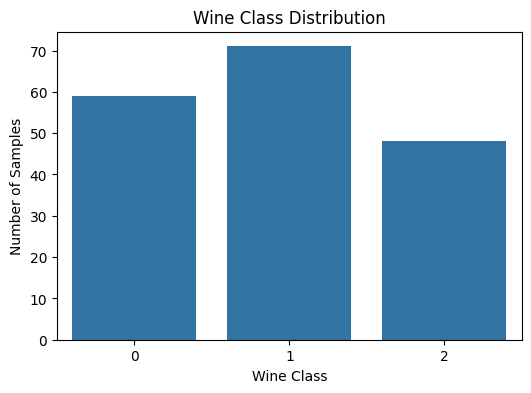

In [ ]:
# Visualize the number of samples in each wine class using a count plot

plt.figure(figsize=(6, 4))

sns.countplot(x=y)
plt.title("Wine Class Distribution")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")

plt.show()

In [ ]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 142
Testing samples: 36


In [ ]:
# Standardize the input features so that they have similar scale and improve neural network training

scaler = StandardScaler()

# Fit scaler only on training data
X_train = scaler.fit_transform(X_train)

# Apply the same transformation to test data
X_test = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [ ]:
# Create a function to build the ANN model with Batch Normalization and Dropout

def build_model(optimizer):

    model = Sequential([

        # First hidden layer
        Dense(64, activation='relu',
              input_shape=(X_train.shape[1],)),

        # Normalize the outputs of the previous layer
        BatchNormalization(),

        # Randomly deactivate 30% neurons during training
        Dropout(0.30),

        # Second hidden layer
        Dense(32, activation='relu'),

        # Apply Batch Normalization
        BatchNormalization(),

        # Apply Dropout regularization
        Dropout(0.30),

        # Output layer for 3-class classification
        Dense(3, activation='softmax')
    ])

    # Compile model using the selected optimizer
    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
# Build the ANN model using the Adam optimizer Learning rate is set to 0.001

adam_model = build_model(
    Adam(learning_rate=0.001)
)

# Display the architecture of the Adam model
adam_model.summary()

C:\Users\SAINATH\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,459 (13.51 KB)

 Trainable params: 3,267 (12.76 KB)

 Non-trainable params: 192 (768.00 B)

In [ ]:
# Define Early Stopping to stop training 

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [ ]:
# Train the ANN model using the Adam optimizer

history_adam = adam_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.20,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 8s 145ms/step - accuracy: 0.4425 - loss: 1.3539 - val_accuracy: 0.6552 - val_loss: 0.8967
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.4690 - loss: 1.1758 - val_accuracy: 0.6897 - val_loss: 0.7999
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.5664 - loss: 0.9631 - val_accuracy: 0.7586 - val_loss: 0.7273
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.6814 - loss: 0.7475 - val_accuracy: 0.8621 - val_loss: 0.6607
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.7257 - loss: 0.6153 - val_accuracy: 0.8966 - val_loss: 0.5985
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.7080 - loss: 0.5933 - val_accuracy: 0.9310 - val_loss: 0.5424
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.7876 - loss: 0.5240 - val_accuracy: 0.9310 - val_loss: 0.4895
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.8673 - loss: 0.4967 - val_accuracy: 0.9655 - val_loss

In [ ]:
# Evaluate the trained Adam model on unseen test data and display test loss and accuracy

adam_loss, adam_accuracy = adam_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Adam Test Accuracy:", adam_accuracy)
print("Adam Test Loss:", adam_loss)

Adam Test Accuracy: 0.9722222089767456
Adam Test Loss: 0.14545390009880066


In [ ]:
# Generate class probabilities for the test data and select the class with the highest probability

y_pred_adam_prob = adam_model.predict(X_test)

y_pred_adam = np.argmax(
    y_pred_adam_prob,
    axis=1
)

print("Predicted Classes:")
print(y_pred_adam)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step
Predicted Classes:
[0 2 0 1 1 0 0 1 1 2 1 2 0 1 0 1 1 0 1 0 1 1 0 0 1 1 0 2 1 2 0 2 1 2 2 2]


In [ ]:
# Generate precision, recall and F1-score for each wine class using the Adam model

print("Adam Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_adam,
        target_names=[str(c) for c in label_encoder.classes_]
    )
)

Adam Classification Report:

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       0.93      1.00      0.97        14
           3       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



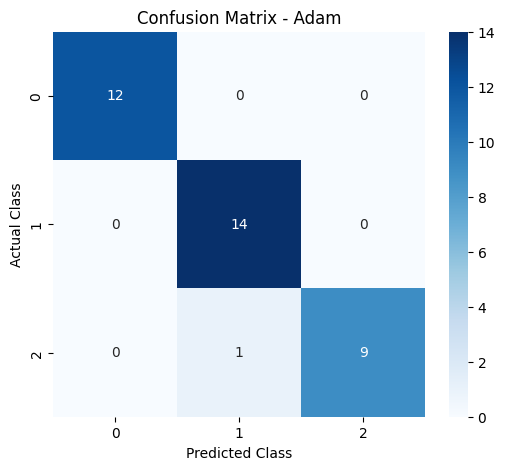

In [ ]:
# Create a confusion matrix to compare actual and predicted wine classes for Adam

cm_adam = confusion_matrix(
    y_test,
    y_pred_adam
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_adam,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix - Adam")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [ ]:
# Build another ANN model using the SGD optimizer Momentum is used to improve the convergence of SGD

sgd_model = build_model(
    SGD(
        learning_rate=0.01,
        momentum=0.9
    )
)

# Display the SGD model architecture
sgd_model.summary()

C:\Users\SAINATH\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,459 (13.51 KB)

 Trainable params: 3,267 (12.76 KB)

 Non-trainable params: 192 (768.00 B)

In [ ]:
# Train the ANN model using the SGD optimizer with validation data and Early Stopping

sgd_early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history_sgd = sgd_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.20,
    callbacks=[sgd_early_stop],
    verbose=1
)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 88ms/step - accuracy: 0.6018 - loss: 0.8930 - val_accuracy: 0.9310 - val_loss: 0.4820
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.8496 - loss: 0.3806 - val_accuracy: 1.0000 - val_loss: 0.2458
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9115 - loss: 0.1865 - val_accuracy: 1.0000 - val_loss: 0.1508
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9115 - loss: 0.2208 - val_accuracy: 1.0000 - val_loss: 0.1150
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.9292 - loss: 0.1635 - val_accuracy: 1.0000 - val_loss: 0.1115
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.9558 - loss: 0.1122 - val_accuracy: 1.0000 - val_loss: 0.0862
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.9469 - loss: 0.2019 - val_accuracy: 1.0000 - val_loss: 0.0607
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.9381 - loss: 0.1426 - val_accuracy: 1.0000 - val_loss:

In [ ]:
# Evaluate the trained SGD model on the test dataset and display its loss and accuracy

sgd_loss, sgd_accuracy = sgd_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("SGD Test Accuracy:", sgd_accuracy)
print("SGD Test Loss:", sgd_loss)

SGD Test Accuracy: 0.9722222089767456
SGD Test Loss: 0.05194200575351715


In [ ]:
# Generate predictions using the SGD model and select the class having the highest probability

y_pred_sgd_prob = sgd_model.predict(X_test)

y_pred_sgd = np.argmax(
    y_pred_sgd_prob,
    axis=1
)

print("Predicted Classes:")
print(y_pred_sgd)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
Predicted Classes:
[0 1 0 1 1 0 0 1 1 2 1 2 0 2 0 1 1 0 1 0 1 1 0 0 1 1 0 2 1 2 0 2 1 2 2 2]


In [ ]:
# Generate precision, recall and F1-score for each wine class using the SGD model

print("SGD Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_sgd,
        target_names=[str(c) for c in label_encoder.classes_]
    )
)

SGD Classification Report:

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       0.93      1.00      0.97        14
           3       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



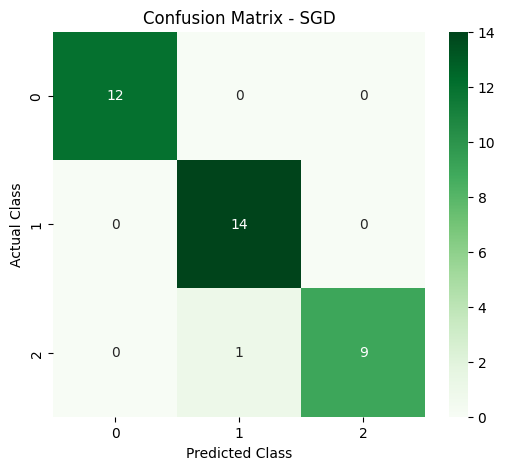

In [ ]:
# Create a confusion matrix to compare actual and predicted wine classes for SGD

cm_sgd = confusion_matrix(
    y_test,
    y_pred_sgd
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_sgd,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("Confusion Matrix - SGD")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [ ]:
# Compare the test accuracy obtained using Adam and SGD optimizers

print("========== OPTIMIZER COMPARISON ==========")

print("Adam Accuracy:", adam_accuracy)
print("SGD Accuracy:", sgd_accuracy)

if adam_accuracy > sgd_accuracy:
    print("\nAdam performed better than SGD.")
elif sgd_accuracy > adam_accuracy:
    print("\nSGD performed better than Adam.")
else:
    print("\nBoth optimizers performed equally.")

========== OPTIMIZER COMPARISON ==========
Adam Accuracy: 0.9722222089767456
SGD Accuracy: 0.9722222089767456

Both optimizers performed equally.
